In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\Projects\Machine Learning\Supervised\Regression\medical_cost_prediction\datasets\insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## Feature Engineering

In [5]:
df['sex'].unique()

array(['female', 'male'], dtype=object)

In [6]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
## converting gender into encoded format.
df['sex'] = df['sex'].apply(lambda x: 0 if x == 'male' else 1)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [8]:
df['smoker'].unique()

array(['yes', 'no'], dtype=object)

In [9]:
## converting smokers into encoded format
df['smoker'] = df['smoker'].apply(lambda x: 0 if x == 'no' else 1)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [10]:
pd.get_dummies(df, prefix=['region'], columns=['region'])

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,False,True,False,False
1334,18,1,31.920,0,0,2205.98080,True,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,False,True


#### One-Hot encoding to regions

000 -> southwest

001 -> southeast

010 -> northwest

100 -> northeast


In [11]:
df_encoded = pd.get_dummies(df, prefix=['region'], columns=['region'], dtype=int)

## df_encoded = df_encoded.str.replace('region_', '', regex = False)
df_encoded.columns = df_encoded.columns.str.removeprefix('region_')
df_encoded.drop('southwest', axis = 1, inplace = True)
df_encoded


,age,sex,bmi,children,smoker,charges,northeast,northwest,southeast
0,19,1,27.900,0,1,16884.92400,0,0,0
1,18,0,33.770,1,0,1725.55230,0,0,1
2,28,0,33.000,3,0,4449.46200,0,0,1
3,33,0,22.705,0,0,21984.47061,0,1,0
4,32,0,28.880,0,0,3866.85520,0,1,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,0,1,0
1334,18,1,31.920,0,0,2205.98080,1,0,0
1335,18,1,36.850,0,0,1629.83350,0,0,1
1336,21,1,25.800,0,0,2007.94500,0,0,0


In [12]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        1338 non-null   int64  
 1   sex        1338 non-null   int64  
 2   bmi        1338 non-null   float64
 3   children   1338 non-null   int64  
 4   smoker     1338 non-null   int64  
 5   charges    1338 non-null   float64
 6   northeast  1338 non-null   int64  
 7   northwest  1338 non-null   int64  
 8   southeast  1338 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 94.2 KB


## Train, Test and Split

In [13]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('charges', axis = 1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape

((1003, 8), (335, 8))

## Standardize the Scaler

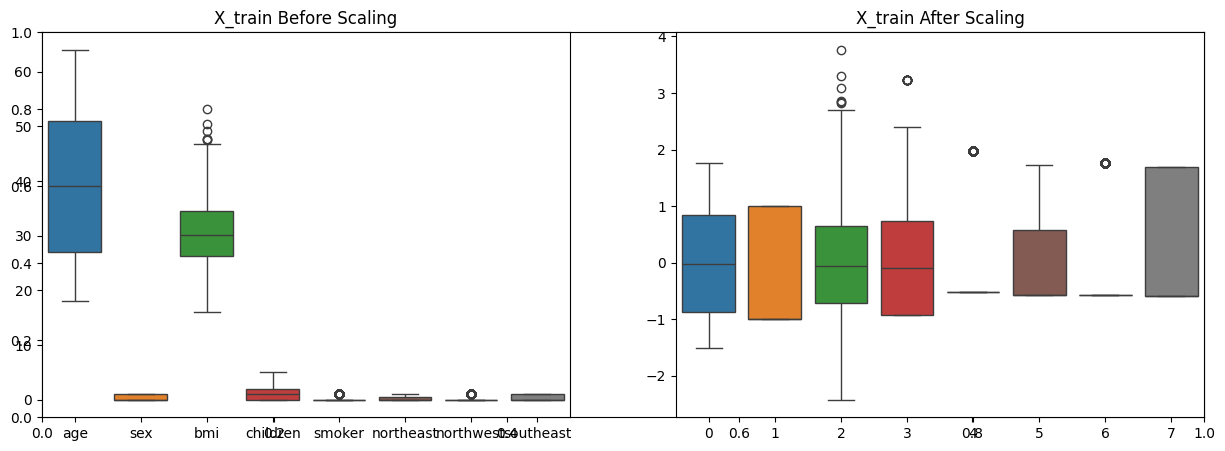

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')

plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

X_train = X_train_scaled
X_test = X_test_scaled

## Linear Regression

In [15]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
y_pred = lin_reg.predict(X_test)

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred)
adjusted_score = 1 - (1-score)*(len(y_test) - 1) / (len(y_test) - X_test.shape[1] -1)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R2 Score: {score}")
print(f"Adjusted R2 Score: {adjusted_score}")

Mean Squared Error: 35117755.73613632
Mean Absolute Error: 4243.654116653146
Root Mean Squared Error: 5926.023602394469
R2 Score: 0.7672642952734356
Adjusted R2 Score: 0.761552989635974


## Polynomial Regression

In [18]:
from sklearn.preprocessing import PolynomialFeatures

poly_reg_lst = []
for i in range(2, 6):
    poly = PolynomialFeatures(degree = i, include_bias = True)
    
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    reg = LinearRegression()
    reg.fit(X_train_poly, y_train)
    poly_reg_lst.append({
        'degree': i,
        'model': reg,
        'x_train' : X_train_poly,
        'x_test' : X_test_poly
    })

In [19]:
for model in poly_reg_lst:
    reg = model['model']
    y_pred = reg.predict(model['x_test'])
    
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    score = r2_score(y_test, y_pred)
    adjusted_score = 1 - (1-score)*(len(y_test) - 1) / (len(y_test) - model['x_test'].shape[1] -1)

    print(f"Degree of the Polynomial: {model['degree']}")
    print(f"Mean Squared Error: {mse}")
    print(f"Mean Absolute Error: {mae}")
    print(f"Root Mean Squared Error: {rmse}")
    print(f"R2 Score: {score}")
    print(f"Adjusted R2 Score: {adjusted_score}")
    print("\n ---------------------------------------------------------------\n")
    
    

Degree of the Polynomial: 2
Mean Squared Error: 21990968.11000611
Mean Absolute Error: 2781.7101811019133
Root Mean Squared Error: 4689.452858277404
R2 Score: 0.854259380947993
Adjusted R2 Score: 0.831566204971037

 ---------------------------------------------------------------

Degree of the Polynomial: 3
Mean Squared Error: 24229055.0187096
Mean Absolute Error: 2965.086200004515
Root Mean Squared Error: 4922.301800855937
R2 Score: 0.8394269201879675
Adjusted R2 Score: 0.6826543866436754

 ---------------------------------------------------------------

Degree of the Polynomial: 4
Mean Squared Error: 42602570.53508286
Mean Absolute Error: 3731.8381634298644
Root Mean Squared Error: 6527.0644653690115
R2 Score: 0.7176602243279757
Adjusted R2 Score: 1.5857235097792306

 ---------------------------------------------------------------

Degree of the Polynomial: 5
Mean Squared Error: 168862565.16224328
Mean Absolute Error: 5558.144904601893
Root Mean Squared Error: 12994.712969598186
R2 S

## Lasso Regression

In [20]:
from sklearn.linear_model import Lasso 

lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

y_pred = lasso_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred)
adjusted_score = 1 - (1-score)*(len(y_test) - 1) / (len(y_test) - X_test.shape[1] -1)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R2 Score: {score}")
print(f"Adjusted R2 Score: {adjusted_score}")

Mean Squared Error: 35117870.103593335
Mean Absolute Error: 4243.395978107447
Root Mean Squared Error: 5926.033251981745
R2 Score: 0.7672635373266322
Adjusted R2 Score: 0.7615522130892489


## Ridge Regression

In [21]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge()

ridge_reg.fit(X_train, y_train)
y_pred = ridge_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred)
adjusted_score = 1 - (1-score)*(len(y_test) - 1) / (len(y_test) - X_test.shape[1] -1)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R2 Score: {score}")
print(f"Adjusted R2 Score: {adjusted_score}")

Mean Squared Error: 35123268.30774937
Mean Absolute Error: 4245.189617154949
Root Mean Squared Error: 5926.488699706544
R2 Score: 0.7672277618386438
Adjusted R2 Score: 0.761515559675175


In [22]:
from sklearn.linear_model import ElasticNet

elastic_net_reg = ElasticNet()
elastic_net_reg.fit(X_train, y_train)

y_pred = elastic_net_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred)
adjusted_score = 1 - (1-score)*(len(y_test) - 1) / (len(y_test) - X_test.shape[1] -1)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R2 Score: {score}")
print(f"Adjusted R2 Score: {adjusted_score}")

Mean Squared Error: 49184755.663069725
Mean Absolute Error: 5245.611079780537
Root Mean Squared Error: 7013.184416730372
R2 Score: 0.6740381459151916
Adjusted R2 Score: 0.6660390820112699
